In [139]:
import mglearn
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt

In [140]:
os.getcwd()

'd:\\NCC-GCSP\\1st sem\\ML\\project\\Term_project'

In [141]:
data = pd.read_csv("./data/METABRIC_RNA_Mutation.csv")

clinical_documented_cols = data.columns[:31].tolist()
mutation_cols = [c for c in data.columns if c.lower().endswith("_mut")]
expression_cols = [
    c for c in data.columns[31:]
    if c not in mutation_cols
]

C:\Users\ASUS\AppData\Local\Temp\ipykernel_13408\1510743806.py:1: DtypeWarning: Columns (678,688,690,692) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv("./data/METABRIC_RNA_Mutation.csv")


In [142]:
from sklearn.model_selection import train_test_split 

In [143]:
data["surv"] = np.where(data["overall_survival"] == 1, 0, 1)
## select the binary outcome
Y = data["surv"]

## Clinical Variables selection
### exclude tumor stage
### include age_at_diagnosis, nottingham_prognostic_index categorical, pam50_and_claudin, er_status, her2_status, pr_status


### Convert npt to dummy variables

In [144]:
npi_cat = pd.cut(
    data["nottingham_prognostic_index"],
    bins=[-np.inf, 2.4, 3.4, 4.4, 5.4, np.inf],
    labels=["excellent", "good", "moderate_1", "moderate_2", "poor"],
    right=True,
)
npi_dummies = pd.get_dummies(npi_cat, prefix="npi", dtype=int)

### Convert status to binary variables

In [145]:
data[["er_status", "pr_status", "her2_status"]] = data[["er_status", "pr_status", "her2_status"]].replace({"Negative": 0, "Positive": 1})
selected_clinical = ["age_at_diagnosis", "er_status", "pr_status", "her2_status"]

C:\Users\ASUS\AppData\Local\Temp\ipykernel_13408\1556225271.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data[["er_status", "pr_status", "her2_status"]] = data[["er_status", "pr_status", "her2_status"]].replace({"Negative": 0, "Positive": 1})


### Choosing columns and splitting data

In [146]:
## combine the selected clinical variables and NPI dummies into a single dataframe
X = pd.concat([data[selected_clinical], npi_dummies], axis=1)
## split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, Y, random_state=0)

In [147]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

X_train = X_train.copy()
X_test = X_test.copy()

X_train[["age_at_diagnosis"]] = scaler.fit_transform(X_train[["age_at_diagnosis"]])  # learn min/max from train
X_test[["age_at_diagnosis"]] = scaler.transform(X_test[["age_at_diagnosis"]])        # reuse train min/max

### Logistic 

In [148]:
## fit logistic regression model
from sklearn.linear_model import LogisticRegression 

logistic_clinical = LogisticRegression(penalty= None).fit(X_train, y_train)


#### Mean accuracy

In [149]:
print('Mean Training Accuracy :',logistic_clinical.score(X_train, y_train))
print('Mean Test Accuracy :',logistic_clinical.score(X_test, y_test))

Mean Training Accuracy : 0.657563025210084
Mean Test Accuracy : 0.7100840336134454


### Lasso regression

### Using cross-validation to select best C

In [150]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
C_values = [0.001, 0.01, 0.1, 1, 10, 100]

results = {}
for C in C_values:
    model = LogisticRegression(penalty='l2', C=C, max_iter=2000)
    scores = cross_val_score(model, X_train, y_train, cv=cv)
    results[C] = scores
    print(f"C={C:<7} | fold accuracies: {scores.round(3)} | mean: {scores.mean():.3f}")

best_C = max(results, key=lambda c: results[c].mean())
print("Best C by mean CV accuracy:", best_C)

C=0.001   | fold accuracies: [0.573 0.573 0.573 0.572 0.575] | mean: 0.574
C=0.01    | fold accuracies: [0.573 0.573 0.573 0.572 0.575] | mean: 0.574
C=0.1     | fold accuracies: [0.643 0.619 0.633 0.674 0.639] | mean: 0.641
C=1       | fold accuracies: [0.654 0.612 0.633 0.695 0.656] | mean: 0.650
C=10      | fold accuracies: [0.657 0.605 0.64  0.688 0.656] | mean: 0.649
C=100     | fold accuracies: [0.657 0.608 0.636 0.688 0.653] | mean: 0.648
Best C by mean CV accuracy: 1


#### so we choose c = 1 for Lasso regression

In [151]:
logistic_clinical_l2 = LogisticRegression(penalty='l2', C=best_C, max_iter=2000).fit(X_train, y_train)
print('Mean Training Accuracy :',logistic_clinical_l2.score(X_train, y_train))
print('Mean Test Accuracy :',logistic_clinical_l2.score(X_test, y_test))

Mean Training Accuracy : 0.657563025210084
Mean Test Accuracy : 0.7100840336134454


### Decision tree   

In [152]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=0)
tree.fit(X_train, y_train)
print('Validation Set Accuracy :',tree.score(X_test, y_test))

Validation Set Accuracy : 0.6197478991596639


### Pre-puring decision tree

In [153]:
tree_4 = DecisionTreeClassifier(max_depth=4, random_state=0) 
tree_4.fit(X_train, y_train)
print('Validation Set Accuracy :',tree_4.score(X_test, y_test))

Validation Set Accuracy : 0.6932773109243697


### Visualization

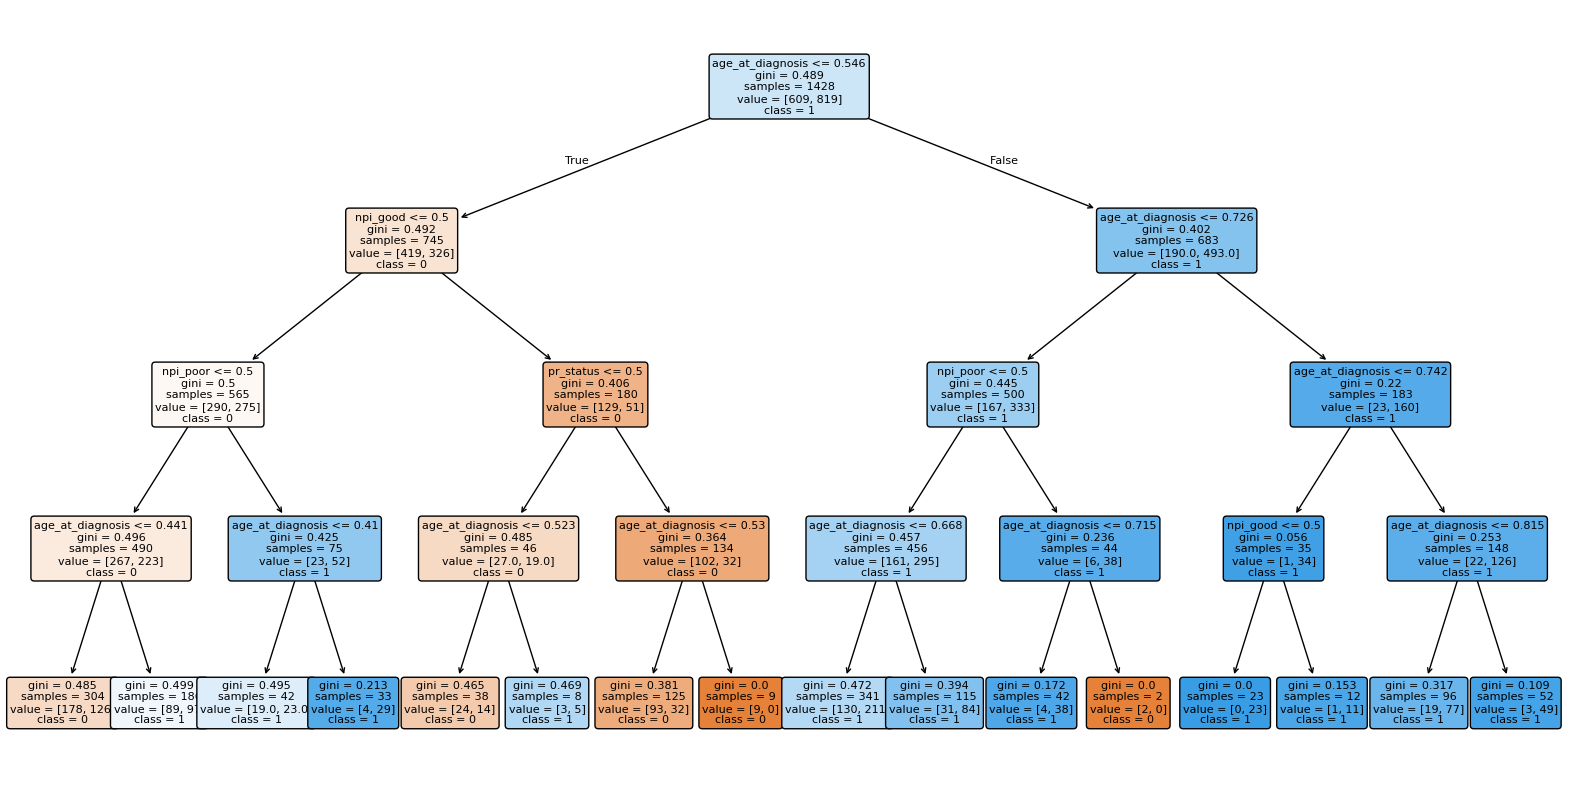

In [154]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))
plot_tree(
    tree_4,
    feature_names=X_train.columns,
    class_names=[str(c) for c in tree_4.classes_],
    filled=True,
    rounded=True,
    fontsize=8,
)
plt.show()

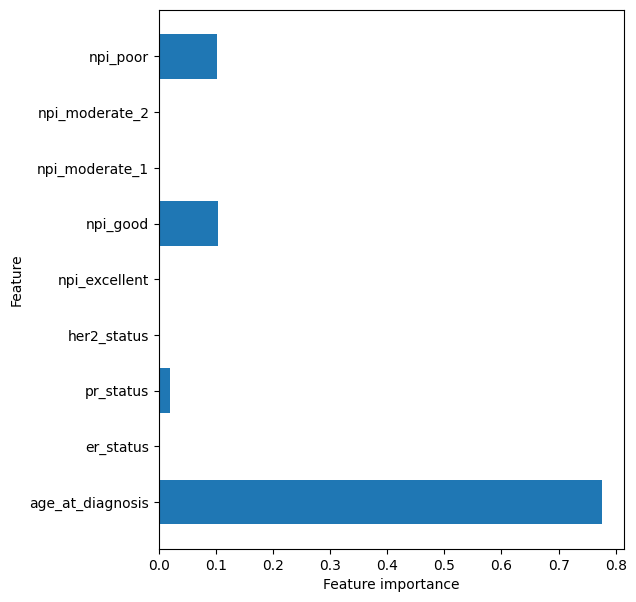

In [155]:
def plot_feature_importances_cancer(model):    
    n_features = X_train.shape[1]
    plt.figure(figsize=(6,7))
    plt.barh(range(n_features), model.feature_importances_, align='center')    
    plt.yticks(np.arange(n_features), X_train.columns)   
    plt.xlabel("Feature importance")    
    plt.ylabel("Feature")
plot_feature_importances_cancer(tree_4)

### Random forest

n_estimators= 10 | train: 0.959 | validation: 0.628
n_estimators= 20 | train: 0.978 | validation: 0.643
n_estimators= 30 | train: 0.987 | validation: 0.641
n_estimators= 40 | train: 0.988 | validation: 0.639
n_estimators= 50 | train: 0.992 | validation: 0.647
n_estimators= 60 | train: 0.993 | validation: 0.647
n_estimators= 70 | train: 0.992 | validation: 0.647
n_estimators= 80 | train: 0.992 | validation: 0.647
n_estimators= 90 | train: 0.992 | validation: 0.658
n_estimators=100 | train: 0.993 | validation: 0.649


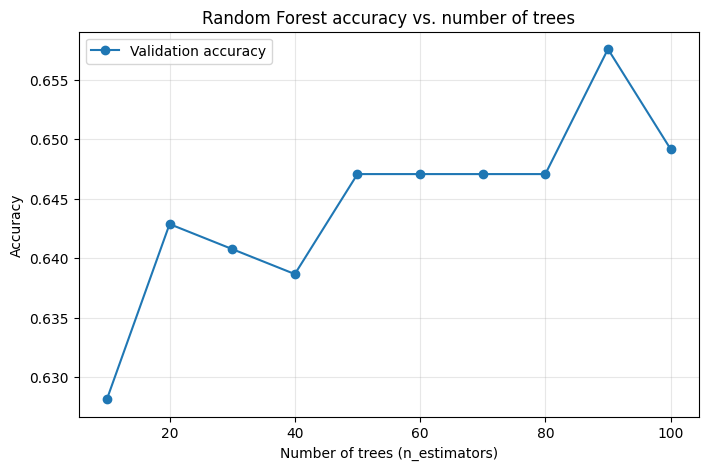

In [156]:
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

n_trees = range(10, 101, 10)   
train_acc = []
test_acc = []

for n in n_trees:
    forest = RandomForestClassifier(n_estimators=n, random_state=2)
    forest.fit(X_train, y_train)
    train_acc.append(forest.score(X_train, y_train))
    test_acc.append(forest.score(X_test, y_test))
    print(f"n_estimators={n:3d} | train: {train_acc[-1]:.3f} | validation: {test_acc[-1]:.3f}")

plt.figure(figsize=(8, 5))
# plt.plot(n_trees, train_acc, marker="o", label="Training accuracy")
plt.plot(n_trees, test_acc, marker="o", label="Validation accuracy")
plt.xlabel("Number of trees (n_estimators)")
plt.ylabel("Accuracy")
plt.title("Random Forest accuracy vs. number of trees")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [157]:
### choose 90 trees for the final model
forest_90 = RandomForestClassifier(n_estimators=90, random_state=2) 
forest_90.fit(X_train, y_train) 
print('Validation Set Accuracy :',forest_90.score(X_test, y_test))

Validation Set Accuracy : 0.657563025210084
